# Titanic Survival Analysis & Prediction

## Python 기반 타이타닉 승객 생존 요인 분석 및 머신러닝 예측

### Project Highlights

- **Dataset:** Titanic3 (1,309 passengers)
- **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn
- **Environment:** Anaconda, Jupyter Notebook
- **Analysis:** EDA, Data Preprocessing, Feature Engineering, Machine Learning
- **Model:** Decision Tree (max_depth=3)
- **Test Accuracy:** 83.59%
- **Baseline Accuracy:** 61.83%
- **Performance Improvement:** +21.76 percentage points
- **5-Fold Cross Validation:** 80.51%

**Key Insight**

성별이 생존 여부 예측에 가장 중요한 변수로 나타났으며,
객실 등급과 가족 규모도 주요 예측 변수로 확인되었습니다.

본 프로젝트에서는 데이터 탐색부터 전처리, 모델 구축,
교차검증, 성능 평가 및 결과 해석까지
데이터 분석의 전체 과정을 수행했습니다.

---

### 1. Project Overview

본 프로젝트는 타이타닉 탑승객 1,309명의 데이터를 활용하여
승객의 생존 여부와 관련된 주요 요인을 탐색하고,
머신러닝을 통해 생존 여부를 예측하는 것을 목표로 합니다.

Python 기반 데이터 분석 교육에서 수행한 실습을 바탕으로,
탐색적 데이터 분석(EDA), 데이터 전처리, 머신러닝 모델링,
모델 성능 평가 과정을 하나의 프로젝트로 재구성합니다.

### 2. Project Objectives

1. 승객의 성별, 나이, 객실 등급 등에 따른 생존율 차이 분석
2. 결측치 처리 및 범주형 변수 변환
3. 의사결정나무 기반 생존 예측 모델 구축
4. 과적합 여부 확인 및 모델 성능 개선
5. 분석 결과 해석 및 주요 시사점 도출

### 3. Tools & Libraries

- Python
- Anaconda / Jupyter Notebook
- Pandas, NumPy
- Matplotlib, Seaborn
- Scikit-learn

### 4. Dataset

- Dataset: Titanic3
- Observations: 1,309 passengers
- Target Variable: survived
  - 0: 사망
  - 1: 생존
  

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

sns.set_theme(style="whitegrid")

print("라이브러리 불러오기 완료!")


라이브러리 불러오기 완료!


In [2]:
# 타이타닉 원본 데이터 불러오기
df = pd.read_excel("titanic.xlsx", sheet_name="titanic3")

# 데이터 크기 확인
print("데이터 크기:", df.shape)

# 데이터 상위 5개 확인
display(df.head())


데이터 크기: (1309, 14)


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"



## 1. Data Understanding

### 1.1 데이터 구조 및 품질 확인

본 분석에서는 타이타닉 탑승객 1,309명의 데이터를 활용합니다.

머신러닝 모델을 구축하기에 앞서 데이터의 변수 구성,
자료형, 결측치 현황 및 기초 통계량을 확인합니다.

이를 통해 데이터의 특성을 이해하고
이후 전처리 방향을 결정하고자 합니다.


In [3]:
# 데이터의 행과 열 확인
print("데이터 크기:", df.shape)

# 변수 이름 확인
print("\n변수 목록:")
print(df.columns.tolist())

# 자료형 및 결측 여부 확인
print("\n데이터 구조:")
df.info()


데이터 크기: (1309, 14)

변수 목록:
['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest']

데이터 구조:
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), object(2), str(5)
memory usage: 200.8+ KB


In [4]:

# 변수별 결측치 개수 및 비율
missing = pd.DataFrame({
    "결측치 개수": df.isnull().sum(),
    "결측 비율(%)": (df.isnull().sum() / len(df) * 100).round(2)
})

# 결측치가 많은 순서로 정렬
missing = missing.sort_values(
    by="결측치 개수",
    ascending=False
)

display(missing)


,결측치 개수,결측 비율(%)
body,1188,90.76
cabin,1014,77.46
boat,823,62.87
home.dest,564,43.09
age,263,20.09
embarked,2,0.15
fare,1,0.08
sibsp,0,0.00
name,0,0.00
survived,0,0.00


In [5]:


# 수치형 변수의 기초 통계량
display(df.describe().round(2))

# 범주형 변수의 기초 통계량
display(df.describe(include=["object", "str"]))



,pclass,survived,age,sibsp,parch,fare,body
count,1309.00,1309.00,1046.00,1309.00,1309.00,1308.00,121.00
mean,2.29,0.38,29.88,0.50,0.39,33.30,160.81
std,0.84,0.49,14.41,1.04,0.87,51.76,97.70
min,1.00,0.00,0.17,0.00,0.00,0.00,1.00
25%,2.00,0.00,21.00,0.00,0.00,7.90,72.00
50%,3.00,0.00,28.00,0.00,0.00,14.45,155.00
75%,3.00,1.00,39.00,1.00,0.00,31.28,256.00
max,3.00,1.00,80.00,8.00,9.00,512.33,328.00


,name,sex,ticket,cabin,embarked,boat,home.dest
count,1309,1309,1309,295,1307,486,745
unique,1307,2,939,186,3,28,369
top,"Connolly, Miss. Kate",male,CA. 2343,C23 C25 C27,S,13,"New York, NY"
freq,2,843,11,6,914,39,64



## 2. Exploratory Data Analysis (EDA)

### 2.1 Overall Survival Rate

타이타닉 탑승객의 전체 생존율을 분석합니다.

전체 생존자와 사망자의 수를 확인하고,
생존율을 계산하여 데이터의 기본적인 특성을 파악합니다.


In [6]:

# 생존자 및 사망자 수
survival_counts = df["survived"].value_counts().sort_index()

# 전체 생존율
survival_rate = df["survived"].mean() * 100

print("전체 승객:", len(df), "명")
print("사망자:", survival_counts[0], "명")
print("생존자:", survival_counts[1], "명")
print(f"전체 생존율: {survival_rate:.2f}%")


전체 승객: 1309 명
사망자: 809 명
생존자: 500 명
전체 생존율: 38.20%


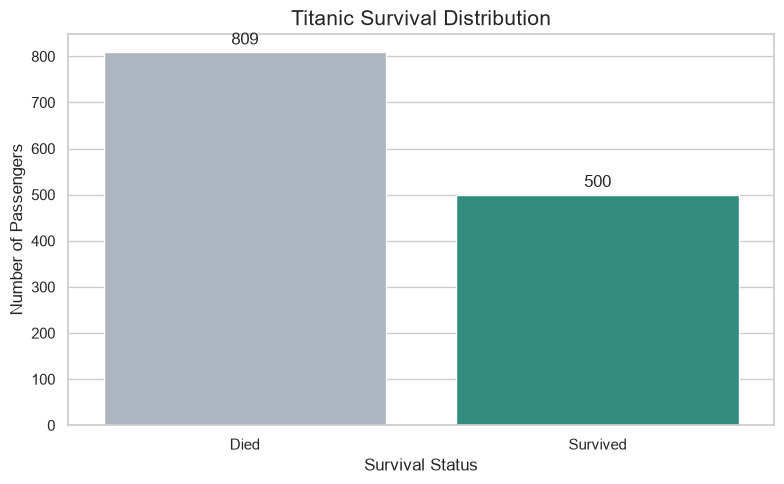

In [7]:

# 생존 여부별 승객 수 시각화
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="survived",
    hue="survived",
    palette={0: "#AAB4C4", 1: "#239C89"},
    legend=False
)

plt.title("Titanic Survival Distribution", fontsize=15)
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")
plt.xticks([0, 1], ["Died", "Survived"])

# 막대 위에 인원 표시
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()



#### Key Findings

- 전체 승객 1,309명 중 500명이 생존하고 809명이 사망했습니다.
- 전체 생존율은 약 38.2%로, 사망자의 비율이 생존자보다 높았습니다.
- 생존 여부의 클래스 비율이 동일하지 않으므로, 머신러닝 모델 평가 시 정확도뿐 아니라 Precision, Recall, F1-score 등의 지표도 함께 검토할 필요가 있습니다.

#### Next Question

전체 생존율에는 성별, 객실 등급, 연령 등의 차이가 반영되어 있습니다.

다음 분석에서는 성별에 따른 생존율 차이를 확인하겠습니다.



### 2.2 Survival Rate by Gender

타이타닉 탑승객의 성별에 따른 생존율 차이를 분석합니다.

남성과 여성의 전체 인원, 생존자 수, 생존율을 비교하여
성별과 생존 여부 사이에 어떤 관계가 있는지 확인합니다.


In [8]:

# 성별에 따른 승객 수, 생존자 수, 생존율 계산
gender_survival = df.groupby("sex")["survived"].agg(
    passengers="count",
    survivors="sum",
    survival_rate="mean"
)

# 생존율을 백분율로 변환
gender_survival["survival_rate"] *= 100

# 결과 출력
display(gender_survival.round(2))


,passengers,survivors,survival_rate
sex,,,
female,466,339,72.75
male,843,161,19.10


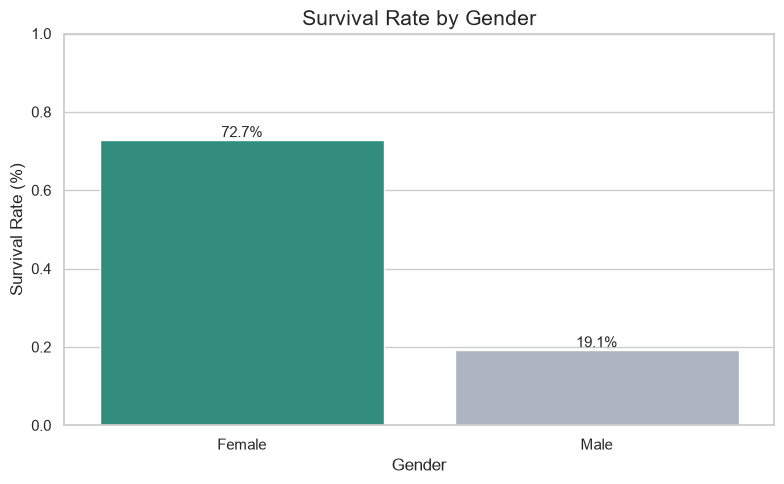

In [9]:

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="sex",
    y="survived",
    hue="sex",
    order=["female", "male"],
    palette={
        "female": "#239C89",
        "male": "#AAB4C4"
    },
    errorbar=None,
    legend=False
)

plt.title("Survival Rate by Gender", fontsize=15)
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks([0, 1], ["Female", "Male"])
plt.ylim(0, 1)

# 막대 위에 생존율 표시
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height * 100:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()



#### Key Findings

- 여성 승객 466명 중 339명이 생존하여 생존율은 약 72.7%였습니다.
- 남성 승객 843명 중 161명이 생존하여 생존율은 약 19.1%였습니다.
- 여성의 생존율이 남성보다 약 53.6%p 높게 나타났습니다.
- 이는 성별과 생존 여부 사이에 뚜렷한 연관성이 있음을 보여줍니다.
- 다만 성별에 따른 차이가 나타났다는 사실만으로 성별 자체가 생존 여부를 결정한 원인이라고 단정할 수는 없습니다.

#### Next Question

성별에 따른 생존율 차이를 확인했습니다.

다음 분석에서는 객실 등급에 따라 생존율이 어떻게 달라지는지 살펴보겠습니다.



### 2.3 Survival Rate by Passenger Class

타이타닉 탑승객의 객실 등급에 따른 생존율 차이를 분석합니다.

1등실, 2등실, 3등실 승객의 전체 인원과 생존자 수,
생존율을 비교하여 객실 등급과 생존 여부의 관계를 확인합니다.


In [10]:

# 객실 등급별 승객 수, 생존자 수, 생존율 계산
class_survival = df.groupby("pclass")["survived"].agg(
    passengers="count",
    survivors="sum",
    survival_rate="mean"
)

# 생존율을 백분율로 변환
class_survival["survival_rate"] *= 100

display(class_survival.round(2))


,passengers,survivors,survival_rate
pclass,,,
1,323,200,61.92
2,277,119,42.96
3,709,181,25.53


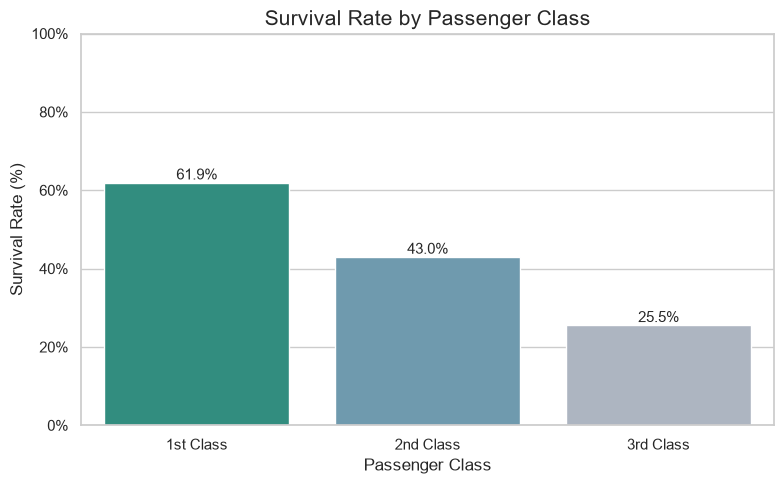

In [11]:

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="pclass",
    y="survived",
    hue="pclass",
    order=[1, 2, 3],
    palette={
        1: "#239C89",
        2: "#659EB8",
        3: "#AAB4C4"
    },
    errorbar=None,
    legend=False
)

plt.title("Survival Rate by Passenger Class", fontsize=15)
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks([0, 1, 2], ["1st Class", "2nd Class", "3rd Class"])

# 실제 생존율을 백분율 축으로 표시
from matplotlib.ticker import PercentFormatter
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.ylim(0, 1)

# 막대 위에 생존율 표시
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height * 100:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()



#### Key Findings

- 1등실 승객의 생존율은 약 61.9%로 가장 높았습니다.
- 2등실 승객의 생존율은 약 43.0%였습니다.
- 3등실 승객의 생존율은 약 25.5%로 가장 낮았습니다.
- 1등실과 3등실의 생존율은 약 36.4%p 차이가 나타났습니다.
- 객실 등급이 높을수록 생존율이 높은 경향이 관찰되었습니다.
- 다만 객실 등급과 생존율의 관계가 반드시 직접적인 인과관계를 의미하는 것은 아닙니다.

#### Next Question

성별과 객실 등급 모두 생존율과 관련이 있는 것으로 나타났습니다.

다음 분석에서는 성별과 객실 등급을 함께 고려하여
각 집단의 생존율이 어떻게 달라지는지 살펴보겠습니다.



### 2.4 Survival Rate by Gender and Passenger Class

앞선 분석에서는 성별과 객실 등급에 따라 생존율에 차이가 있음을 확인했습니다.

이번 분석에서는 성별과 객실 등급을 함께 고려하여
동일한 객실 등급 내에서도 성별에 따른 생존율 차이가 나타나는지 확인합니다.

이를 통해 개별 변수 분석만으로는 파악하기 어려운
집단별 생존 패턴을 탐색하고자 합니다.


In [12]:

# 성별 및 객실 등급별 승객 수, 생존자 수, 생존율
gender_class_survival = df.groupby(
    ["pclass", "sex"]
)["survived"].agg(
    passengers="count",
    survivors="sum",
    survival_rate="mean"
)

# 생존율을 백분율로 변환
gender_class_survival["survival_rate"] *= 100

display(gender_class_survival.round(2))


passengers  survivors  survival_rate
pclass sex                                         
1      female         144        139          96.53
       male           179         61          34.08
2      female         106         94          88.68
       male           171         25          14.62
3      female         216        106          49.07
       male           493         75          15.21

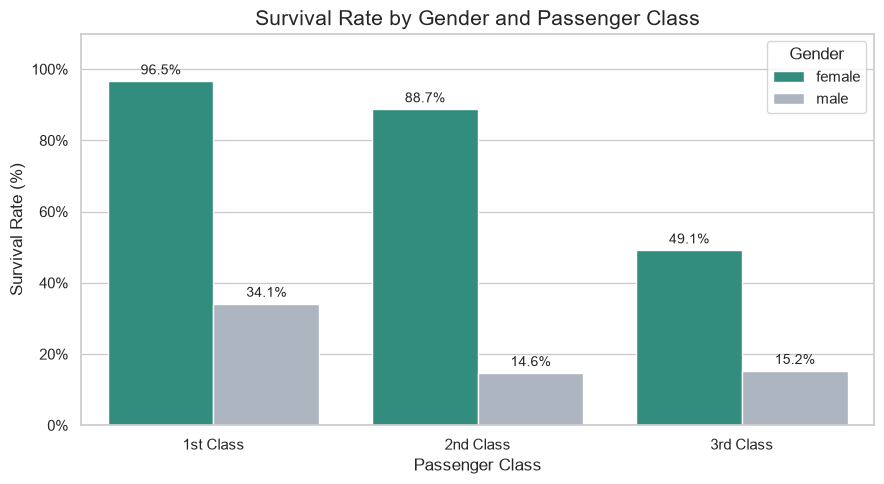

In [13]:

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=df,
    x="pclass",
    y="survived",
    hue="sex",
    order=[1, 2, 3],
    hue_order=["female", "male"],
    palette={
        "female": "#239C89",
        "male": "#AAB4C4"
    },
    errorbar=None
)

plt.title(
    "Survival Rate by Gender and Passenger Class",
    fontsize=15
)

plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")

plt.xticks(
    [0, 1, 2],
    ["1st Class", "2nd Class", "3rd Class"]
)

from matplotlib.ticker import PercentFormatter
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.ylim(0, 1.1)

plt.legend(title="Gender")

# 막대 위에 생존율 표시
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{bar.get_height() * 100:.1f}%"
            for bar in container
        ],
        padding=3,
        fontsize=10
    )

plt.tight_layout()
plt.show()



#### Key Findings

- 모든 객실 등급에서 여성의 생존율이 남성보다 높게 나타났습니다.
- 1등실 여성의 생존율은 약 96.5%로 가장 높았습니다.
- 2등실 남성의 생존율은 약 14.6%로 가장 낮았습니다.
- 3등실 여성의 생존율(49.1%)은 1등실 남성(34.1%)보다 약 15.0%p 높았습니다.
- 여성 집단에서는 객실 등급에 따른 생존율 차이가 크게 나타났으며, 남성 집단에서도 등급별 차이가 관찰되었습니다.
- 이러한 결과는 성별과 객실 등급을 함께 고려하면 집단별 생존 패턴을 더 구체적으로 파악할 수 있음을 보여줍니다.

#### Next Question

성별과 객실 등급에 따른 생존율 차이를 확인했습니다.

다음 분석에서는 승객의 연령과 생존 여부 사이의 관계를 살펴보겠습니다.



### 2.5 Survival Rate by Age Group

타이타닉 탑승객의 연령에 따른 생존율 차이를 분석합니다.

먼저 전체 승객의 연령 분포를 확인한 후,
연령대를 구분하여 집단별 생존율을 비교합니다.

나이 정보가 누락된 승객은 본 탐색적 분석에서 제외하며,
머신러닝 단계에서는 별도의 결측치 처리 방법을 적용합니다.


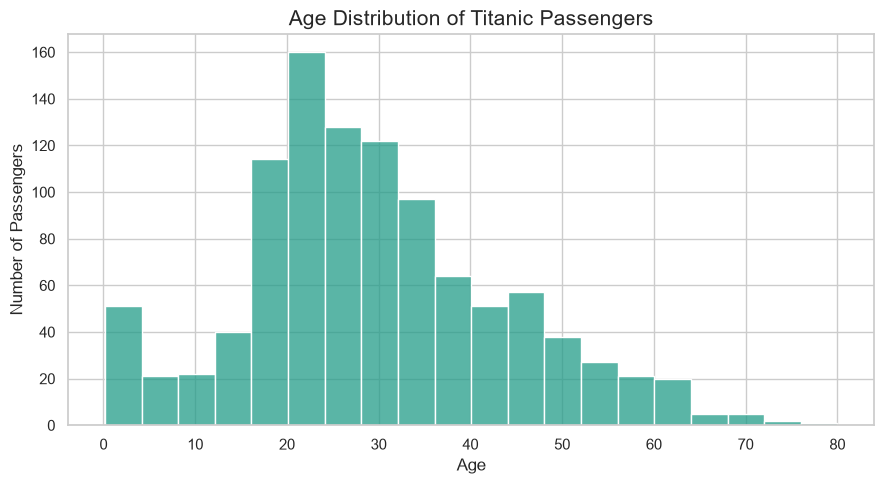

In [14]:

# 연령 분포 시각화
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    color="#239C89",
    edgecolor="white"
)

plt.title("Age Distribution of Titanic Passengers", fontsize=15)
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()


In [15]:

# 연령대 구분
age_bins = [0, 5, 12, 19, 39, 59, float("inf")]

age_labels = [
    "Infant",
    "Child",
    "Teenager",
    "Young Adult",
    "Middle-aged",
    "Senior"
]

# 원본 데이터는 유지하고 분석용 복사본 생성
eda_df = df.copy()

eda_df["age_group"] = pd.cut(
    eda_df["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# 연령대별 생존율 계산
age_survival = eda_df.groupby(
    "age_group",
    observed=True
)["survived"].agg(
    passengers="count",
    survivors="sum",
    survival_rate="mean"
)

age_survival["survival_rate"] *= 100

display(age_survival.round(2))


,passengers,survivors,survival_rate
age_group,,,
Infant,56,37,66.07
Child,38,17,44.74
Teenager,131,52,39.69
Young Adult,576,225,39.06
Middle-aged,205,84,40.98
Senior,40,12,30.00


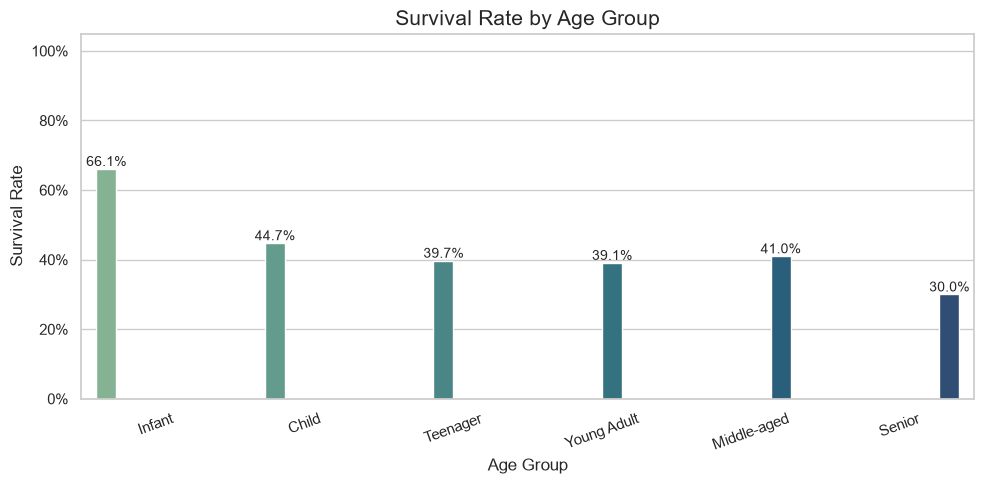

In [16]:

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=eda_df,
    x="age_group",
    y="survived",
    hue="age_group",
    order=age_labels,
    palette="crest",
    errorbar=None,
    legend=False
)

plt.title("Survival Rate by Age Group", fontsize=15)
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")

from matplotlib.ticker import PercentFormatter
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.ylim(0, 1.05)

plt.xticks(rotation=20)

for bar in ax.patches:
    height = bar.get_height()
    if not np.isnan(height):
        ax.annotate(
            f"{height * 100:.1f}%",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.tight_layout()
plt.show()



#### Key Findings

- 나이 정보가 확인된 승객 1,046명을 대상으로 연령대별 생존율을 분석했습니다.
- 영유아(0–5세)는 56명 중 37명이 생존하여 66.1%로 가장 높은 생존율을 보였습니다.
- 고령층(60세 이상)은 40명 중 12명이 생존하여 30.0%로 가장 낮은 생존율을 보였습니다.
- 영유아와 고령층의 생존율 차이는 약 36.1%p였습니다.
- 청년층(20–39세)의 생존율은 39.1%, 중장년층(40–59세)은 41.0%로, 연령이 증가할수록 생존율이 일관되게 감소하지는 않았습니다.
- 영유아와 고령층의 표본 수가 상대적으로 적고, 나이 결측치 263명이 제외되었으므로 결과를 일반화할 때 주의가 필요합니다.

#### Next Question

연령대별 생존율을 비교한 결과, 영유아의 생존율이 상대적으로 높게 나타났습니다.

다음 분석에서는 승객의 가족 구성과 동반 가족 수가 생존 여부와 어떤 관계가 있는지 살펴보겠습니다.


In [17]:

# 연령대별 승객 수와 생존율 확인
display(age_survival.round(2))


,passengers,survivors,survival_rate
age_group,,,
Infant,56,37,66.07
Child,38,17,44.74
Teenager,131,52,39.69
Young Adult,576,225,39.06
Middle-aged,205,84,40.98
Senior,40,12,30.00



### 2.6 Survival Rate by Family Size

타이타닉 탑승객의 가족 구성과 생존율 사이의 관계를 분석합니다.

기존 데이터의 sibsp(동반 형제자매 및 배우자 수)와
parch(동반 부모 및 자녀 수)를 활용하여
승객 본인을 포함한 가족 규모(family_size) 변수를 생성합니다.

이를 통해 혼자 탑승한 승객과 가족을 동반한 승객의
생존율을 비교하고, 가족 규모에 따른 생존 패턴을 탐색합니다.


In [18]:

# 원본 데이터는 유지하고 분석용 데이터 사용
eda_df = df.copy()

# 가족 규모 변수 생성 (본인 포함)
eda_df["family_size"] = (
    eda_df["sibsp"] + eda_df["parch"] + 1
)

# 가족 규모별 승객 수 확인
display(
    eda_df["family_size"]
    .value_counts()
    .sort_index()
)


family_size
1     790
2     235
3     159
4      43
5      22
6      25
7      16
8       8
11     11
Name: count, dtype: int64

In [19]:

# 가족 규모별 승객 수, 생존자 수, 생존율 계산
family_survival = eda_df.groupby(
    "family_size"
)["survived"].agg(
    passengers="count",
    survivors="sum",
    survival_rate="mean"
)

# 생존율 백분율 변환
family_survival["survival_rate"] *= 100

display(family_survival.round(2))


,passengers,survivors,survival_rate
family_size,,,
1,790,239,30.25
2,235,126,53.62
3,159,90,56.60
4,43,30,69.77
5,22,6,27.27
6,25,5,20.00
7,16,4,25.00
8,8,0,0.00
11,11,0,0.00


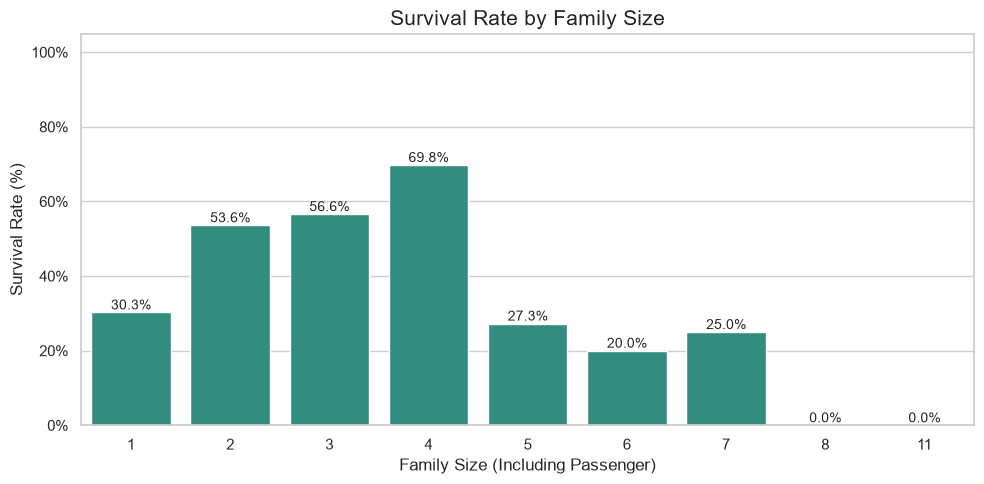

In [20]:

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=eda_df,
    x="family_size",
    y="survived",
    color="#239C89",
    errorbar=None
)

plt.title("Survival Rate by Family Size", fontsize=15)
plt.xlabel("Family Size (Including Passenger)")
plt.ylabel("Survival Rate (%)")

from matplotlib.ticker import PercentFormatter
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 1.05)

# 막대 위에 생존율 표시
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{height * 100:.1f}%",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()


In [21]:

# 혼자 탑승했는지 여부를 구분하는 변수 생성
eda_df["travel_group"] = np.where(
    eda_df["family_size"] == 1,
    "Alone",
    "With Family"
)

# 동반 여부에 따른 생존율 계산
travel_survival = eda_df.groupby(
    "travel_group"
)["survived"].agg(
    passengers="count",
    survivors="sum",
    survival_rate="mean"
)

travel_survival["survival_rate"] *= 100

display(travel_survival.round(2))


,passengers,survivors,survival_rate
travel_group,,,
Alone,790,239,30.25
With Family,519,261,50.29



#### Additional Findings: Traveling Alone vs. With Family

- 혼자 탑승한 승객은 790명으로 전체의 약 60.4%를 차지했습니다.
- 혼자 탑승한 승객의 생존율은 30.25%였습니다.
- 가족을 동반한 승객 519명의 생존율은 50.29%였습니다.
- 가족 동반 승객의 생존율이 혼자 탑승한 승객보다 약 20.04%p 높게 나타났습니다.
- 다만 가족 규모별 분석에서는 5명 이상 집단의 생존율이 상대적으로 낮았으므로, 가족 동반 여부뿐 아니라 가족 규모도 함께 고려할 필요가 있습니다.
- 이러한 차이는 관찰된 연관성이며, 성별이나 객실 등급 등의 영향을 통제한 인과적 효과를 의미하지는 않습니다.



### 2.7 EDA Summary & Key Insights

앞선 탐색적 데이터 분석(EDA)을 통해 타이타닉 승객의
생존 여부와 관련된 주요 특성을 확인했습니다.

성별, 객실 등급, 연령, 가족 구성에 따른 생존율을 비교하고,
개별 변수 및 변수 간 교차 분석을 수행했습니다.

이번 단계에서는 주요 분석 결과를 종합하고,
머신러닝 모델 구축을 위한 변수 선정 방향을 설정합니다.


In [22]:

# EDA 주요 분석 결과 요약
eda_summary = pd.DataFrame({
    "Analysis": [
        "Overall Survival",
        "Female",
        "Male",
        "1st Class",
        "2nd Class",
        "3rd Class",
        "Infant (0-5)",
        "Senior (60+)",
        "Alone",
        "With Family"
    ],
    "Survival Rate (%)": [
        df["survived"].mean() * 100,
        gender_survival.loc["female", "survival_rate"],
        gender_survival.loc["male", "survival_rate"],
        class_survival.loc[1, "survival_rate"],
        class_survival.loc[2, "survival_rate"],
        class_survival.loc[3, "survival_rate"],
        age_survival.loc["Infant", "survival_rate"],
        age_survival.loc["Senior", "survival_rate"],
        travel_survival.loc["Alone", "survival_rate"],
        travel_survival.loc["With Family", "survival_rate"]
    ]
})

display(eda_summary.round(2))


,Analysis,Survival Rate (%)
0,Overall Survival,38.20
1,Female,72.75
2,Male,19.10
3,1st Class,61.92
4,2nd Class,42.96
5,3rd Class,25.53
6,Infant (0-5),66.07
7,Senior (60+),30.00
8,Alone,30.25
9,With Family,50.29



#### Overall Key Findings

**1. 성별과 생존 여부 사이에 뚜렷한 연관성이 관찰되었습니다.**

- 여성의 생존율은 약 72.7%, 남성은 약 19.1%였습니다.
- 성별에 따른 생존율 차이는 약 53.6%p였습니다.
- 모든 객실 등급에서 여성의 생존율이 남성보다 높았습니다.

**2. 객실 등급에 따라 생존율 차이가 나타났습니다.**

- 1등실 승객의 생존율은 약 61.9%로 가장 높았습니다.
- 3등실 승객의 생존율은 약 25.5%로 가장 낮았습니다.
- 객실 등급이 높을수록 생존율이 높은 경향이 관찰되었습니다.

**3. 연령대에 따른 생존율 차이가 확인되었습니다.**

- 영유아(0–5세)의 생존율은 66.1%로 가장 높았습니다.
- 고령층(60세 이상)의 생존율은 30.0%로 가장 낮았습니다.
- 연령과 생존율 사이에 일관된 선형 관계는 확인되지 않았습니다.
- 나이 결측치 263명이 제외되었으므로 결과 해석에 주의가 필요합니다.

**4. 가족 구성과 생존 여부 사이에 비선형적인 관계가 관찰되었습니다.**

- 혼자 탑승한 승객의 생존율은 30.3%였습니다.
- 가족 동반 승객의 생존율은 50.3%였습니다.
- 가족 규모가 4명인 집단의 생존율은 69.8%로 가장 높았습니다.
- 가족 규모가 5명 이상인 집단에서는 생존율이 낮아지는 경향이 관찰되었습니다.

**5. 변수 간 교차 분석의 필요성을 확인했습니다.**

- 3등실 여성의 생존율은 약 49.1%로, 1등실 남성의 34.1%보다 높았습니다.
- 따라서 개별 변수뿐 아니라 여러 변수를 함께 고려하여 생존 여부를 예측할 필요가 있습니다.

#### Limitations

- 본 분석은 관찰 데이터에 기반하므로 인과관계를 직접 입증하지 않습니다.
- 일부 연령대 및 가족 규모 집단은 표본 수가 적습니다.
- 연령 결측치가 존재하며, 일부 변수는 사고 이후의 정보를 포함하고 있습니다.
- 머신러닝 단계에서는 데이터 누수를 방지하고 별도의 테스트 데이터로 예측 성능을 평가해야 합니다.



### 2.8 Feature Selection Strategy

EDA 결과를 바탕으로 머신러닝 모델에 사용할 입력 변수의 후보를 선정합니다.

#### Candidate Features

- pclass: 객실 등급
- sex: 성별
- age: 나이
- fare: 운임
- sibsp: 형제자매 및 배우자 수
- parch: 부모 및 자녀 수
- embarked: 승선 항구
- family_size: 승객 본인을 포함한 가족 규모

#### Target Variable

- survived: 생존 여부 (0 = 사망, 1 = 생존)

#### Data Leakage Prevention

사고 이후에 확인할 수 있는 boat(구명정 정보)와
body(시신 식별 번호)는 입력 변수에서 제외합니다.

또한 데이터 전처리 과정에서 발생할 수 있는 정보 누수를 방지하기 위해
훈련 데이터와 테스트 데이터를 먼저 분리한 후,
훈련 데이터만을 기준으로 결측치 대체 및 인코딩을 수행합니다.

#### Modeling Strategy

1. 기준 모델(Dummy Classifier) 구축
2. 의사결정나무(Decision Tree) 모델 학습
3. 모델 복잡도 조정 및 과적합 검토
4. 추가 알고리즘과의 성능 비교
5. 교차검증 및 테스트 데이터 평가
6. 주요 예측 변수와 모델의 한계 해석



## 3. Data Preprocessing

머신러닝 모델 학습을 위해 데이터를 전처리합니다.

데이터 전처리는 모델이 학습할 수 있는 형태로 데이터를 변환하는 과정입니다.

본 프로젝트에서는 다음 과정을 수행합니다.

1. 입력 변수와 예측 대상 변수 분리
2. 훈련 데이터와 테스트 데이터 분할
3. 결측치 처리
4. 범주형 변수 인코딩
5. 머신러닝 학습용 데이터 구성

데이터 누수를 방지하기 위해 훈련 데이터와 테스트 데이터를 먼저 분리하고, 결측치 대체 및 인코딩은 훈련 데이터만을 기준으로 학습합니다.

### 3.1 Train-Test Split

전체 데이터를 훈련용 80%, 테스트용 20%로 분리합니다.

훈련 데이터는 머신러닝 모델 학습에 사용하고, 테스트 데이터는 학습이 완료된 모델의 예측 성능을 평가하는 데 사용합니다.


In [23]:

# 머신러닝에 사용할 입력 변수 선정
features = [
    "pclass",
    "sex",
    "age",
    "fare",
    "sibsp",
    "parch",
    "embarked"
]

# 입력 변수 데이터 생성
X = df[features].copy()

# 가족 규모 변수 추가
X["family_size"] = X["sibsp"] + X["parch"] + 1

# 예측 대상 변수
y = df["survived"].copy()

# 데이터 크기 확인
print("입력 데이터 크기:", X.shape)
print("예측 대상 크기:", y.shape)

display(X.head())


입력 데이터 크기: (1309, 8)
예측 대상 크기: (1309,)


,pclass,sex,age,fare,sibsp,parch,embarked,family_size
0,1,female,29.0000,211.3375,0,0,S,1
1,1,male,0.9167,151.5500,1,2,S,4
2,1,female,2.0000,151.5500,1,2,S,4
3,1,male,30.0000,151.5500,1,2,S,4
4,1,female,25.0000,151.5500,1,2,S,4


In [24]:

from sklearn.model_selection import train_test_split

# 훈련 데이터 80%, 테스트 데이터 20% 분리
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 데이터 크기 확인
print("훈련 입력 데이터:", X_train.shape)
print("테스트 입력 데이터:", X_test.shape)
print("훈련 정답 데이터:", y_train.shape)
print("테스트 정답 데이터:", y_test.shape)


훈련 입력 데이터: (1047, 8)
테스트 입력 데이터: (262, 8)
훈련 정답 데이터: (1047,)
테스트 정답 데이터: (262,)


In [25]:

# 전체 데이터와 분할 데이터의 생존율 확인
print(f"전체 데이터 생존율: {y.mean() * 100:.2f}%")
print(f"훈련 데이터 생존율: {y_train.mean() * 100:.2f}%")
print(f"테스트 데이터 생존율: {y_test.mean() * 100:.2f}%")


전체 데이터 생존율: 38.20%
훈련 데이터 생존율: 38.20%
테스트 데이터 생존율: 38.17%



### 3.2 Missing Value Handling & Categorical Encoding

머신러닝 모델 학습을 위해 결측치 처리와 범주형 변수 인코딩을 수행합니다.

#### Preprocessing Strategy

- 수치형 변수(pclass, age, fare, sibsp, parch, family_size)는 중앙값으로 결측치를 대체합니다.
- 범주형 변수(sex, embarked)는 최빈값으로 결측치를 대체합니다.
- 범주형 변수는 One-Hot Encoding을 적용하여 숫자형 데이터로 변환합니다.
- 훈련 데이터에서 학습한 전처리 기준을 테스트 데이터에 동일하게 적용합니다.
- Pipeline과 ColumnTransformer를 활용하여 데이터 누수를 방지합니다.


In [26]:

# 데이터 전처리에 필요한 라이브러리
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [27]:

# 수치형 변수
numeric_features = [
    "pclass",
    "age",
    "fare",
    "sibsp",
    "parch",
    "family_size"
]

# 범주형 변수
categorical_features = [
    "sex",
    "embarked"
]

print("수치형 변수:", numeric_features)
print("범주형 변수:", categorical_features)


수치형 변수: ['pclass', 'age', 'fare', 'sibsp', 'parch', 'family_size']
범주형 변수: ['sex', 'embarked']


In [28]:

# 수치형 데이터 전처리
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# 범주형 데이터 전처리
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# 수치형과 범주형 전처리 결합
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("전처리 Pipeline 생성 완료!")


전처리 Pipeline 생성 완료!


In [29]:

# 훈련 데이터로만 전처리 기준 학습
X_train_processed = preprocessor.fit_transform(X_train)

# 테스트 데이터에는 학습된 기준만 적용
X_test_processed = preprocessor.transform(X_test)

# 전처리 후 데이터 크기 확인
print("전처리 전 훈련 데이터:", X_train.shape)
print("전처리 후 훈련 데이터:", X_train_processed.shape)

print("전처리 전 테스트 데이터:", X_test.shape)
print("전처리 후 테스트 데이터:", X_test_processed.shape)

# 전처리 후 변수명 확인
print("\n전처리 후 변수명:")
print(preprocessor.get_feature_names_out())


전처리 전 훈련 데이터: (1047, 8)
전처리 후 훈련 데이터: (1047, 11)
전처리 전 테스트 데이터: (262, 8)
전처리 후 테스트 데이터: (262, 11)

전처리 후 변수명:
['num__pclass' 'num__age' 'num__fare' 'num__sibsp' 'num__parch'
 'num__family_size' 'cat__sex_female' 'cat__sex_male' 'cat__embarked_C'
 'cat__embarked_Q' 'cat__embarked_S']


In [30]:

# 전처리 결과 검증
import numpy as np

print("훈련 데이터 결측치 수:",
      np.isnan(X_train_processed).sum())

print("테스트 데이터 결측치 수:",
      np.isnan(X_test_processed).sum())

print("훈련 데이터 무한대 값 수:",
      np.isinf(X_train_processed).sum())

print("테스트 데이터 무한대 값 수:",
      np.isinf(X_test_processed).sum())


훈련 데이터 결측치 수: 0
테스트 데이터 결측치 수: 0
훈련 데이터 무한대 값 수: 0
테스트 데이터 무한대 값 수: 0



## 4. Machine Learning

탐색적 데이터 분석과 전처리를 완료한 후,
승객의 생존 여부를 예측하는 머신러닝 모델을 구축합니다.

### 4.1 Baseline Model vs. Decision Tree

먼저 Dummy Classifier를 기준 모델로 설정하고,
Decision Tree Classifier와 예측 성능을 비교합니다.

두 모델의 성능을 비교하여 머신러닝 학습이
단순한 다수 클래스 예측보다 효과적인지 확인합니다.


In [31]:

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 기준 모델 생성
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# 의사결정나무 모델 생성
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# 훈련 데이터로 모델 학습
dummy_model.fit(X_train_processed, y_train)
tree_model.fit(X_train_processed, y_train)

print("두 모델의 학습이 완료되었습니다.")


두 모델의 학습이 완료되었습니다.


In [32]:

# 테스트 데이터 예측
dummy_pred = dummy_model.predict(X_test_processed)
tree_pred = tree_model.predict(X_test_processed)

# 정확도 계산
dummy_accuracy = accuracy_score(y_test, dummy_pred)
tree_accuracy = accuracy_score(y_test, tree_pred)

# 성능 비교
print(f"Dummy Classifier 정확도: {dummy_accuracy * 100:.2f}%")
print(f"Decision Tree 정확도: {tree_accuracy * 100:.2f}%")

print(
    f"정확도 차이: {(tree_accuracy - dummy_accuracy) * 100:.2f}%p"
)


Dummy Classifier 정확도: 61.83%
Decision Tree 정확도: 83.59%
정확도 차이: 21.76%p



### 4.2 Model Evaluation

Dummy Classifier와 Decision Tree 모델의 예측 성능을 보다 구체적으로 평가합니다.

정확도(Accuracy)뿐 아니라 정밀도(Precision), 재현율(Recall),
F1-score를 활용하여 모델의 성능을 비교합니다.

특히 생존자(1)를 올바르게 예측하는 능력과
실제 생존자를 사망자로 잘못 분류하는 경우를 함께 확인합니다.


In [33]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 모델별 평가 지표 계산
evaluation_results = pd.DataFrame({
    "Model": ["Dummy Classifier", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, dummy_pred),
        accuracy_score(y_test, tree_pred)
    ],
    "Precision": [
        precision_score(y_test, dummy_pred, zero_division=0),
        precision_score(y_test, tree_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, dummy_pred, zero_division=0),
        recall_score(y_test, tree_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, dummy_pred, zero_division=0),
        f1_score(y_test, tree_pred, zero_division=0)
    ]
})

# 백분율로 변환
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
evaluation_results[metrics] *= 100

display(evaluation_results.round(2))


,Model,Accuracy,Precision,Recall,F1-score
0,Dummy Classifier,61.83,0.00,0.0,0.00
1,Decision Tree,83.59,81.32,74.0,77.49


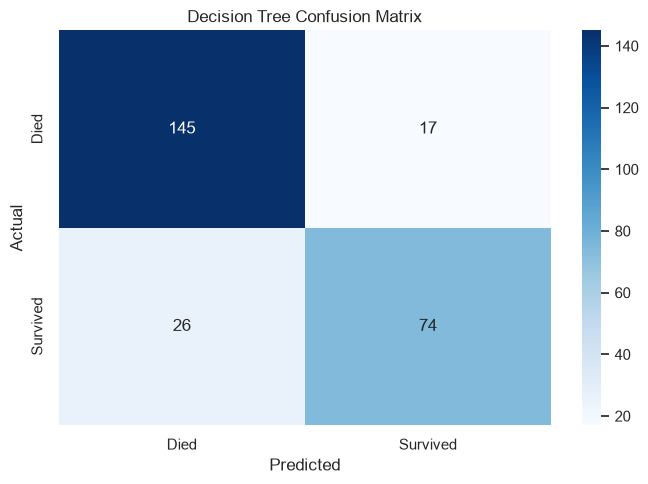

In [34]:

from sklearn.metrics import confusion_matrix

# 의사결정나무 혼동행렬 계산
cm = confusion_matrix(y_test, tree_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Died", "Survived"],
    yticklabels=["Died", "Survived"]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()



#### Key Findings: Model Evaluation

**1. 모델 정확도**

- Dummy Classifier의 정확도는 61.83%였습니다.
- Decision Tree의 정확도는 83.59%로 기준 모델보다 21.76%p 높았습니다.
- 전체 테스트 승객 262명 중 219명을 정확하게 예측했습니다.

**2. 생존자 예측 성능**

- Precision: 81.32%
- Recall: 74.00%
- F1-score: 77.49%
- 실제 생존자 100명 중 74명을 생존자로 정확하게 예측했습니다.

**3. 혼동행렬 분석**

- True Negative: 145명
- False Positive: 17명
- False Negative: 26명
- True Positive: 74명

**4. 모델의 한계**

- 실제 생존자 26명을 사망자로 잘못 분류했습니다.
- 사망자 분류 성능에 비해 생존자 재현율이 낮았습니다.
- 단일 테스트 데이터의 결과이므로 모델의 일반화 성능을 추가로 검증할 필요가 있습니다.

#### Next Step

훈련 데이터와 테스트 데이터의 성능 차이를 확인하여
과적합 여부를 검토하고, 교차검증을 통해 모델의 안정성을 평가합니다.



### 4.3 Overfitting Analysis

머신러닝 모델이 훈련 데이터에 과도하게 적합되는 현상을 과적합(Overfitting)이라고 합니다.

훈련 데이터에서의 정확도와 테스트 데이터에서의 정확도를 비교하여
모델의 일반화 성능을 확인합니다.

훈련 정확도가 테스트 정확도보다 지나치게 높다면
과적합 가능성을 검토할 필요가 있습니다.


In [35]:

# 훈련 데이터 정확도
train_accuracy = tree_model.score(
    X_train_processed, y_train
)

# 테스트 데이터 정확도
test_accuracy = tree_model.score(
    X_test_processed, y_test
)

# 성능 차이
accuracy_gap = train_accuracy - test_accuracy

print(f"훈련 정확도: {train_accuracy * 100:.2f}%")
print(f"테스트 정확도: {test_accuracy * 100:.2f}%")
print(f"정확도 차이: {accuracy_gap * 100:.2f}%p")


훈련 정확도: 81.18%
테스트 정확도: 83.59%
정확도 차이: -2.40%p



#### Key Findings: Overfitting Analysis

- Decision Tree의 훈련 정확도는 81.18%입니다.
- 테스트 정확도는 83.59%로 훈련 정확도보다 약 2.40%p 높게 나타났습니다.
- 현재 결과에서는 훈련 데이터에 대한 뚜렷한 과적합 징후가 확인되지 않았습니다.
- 다만 단일 데이터 분할 결과만으로 모델의 일반화 성능을 확정하기는 어렵습니다.
- 따라서 교차검증을 통해 모델 성능의 안정성을 추가로 평가할 필요가 있습니다.

#### Next Step

5-Fold Cross Validation을 적용하여 훈련 데이터 내에서
모델의 평균 정확도와 성능 변동성을 확인합니다.



### 4.4 Cross Validation

모델의 일반화 성능과 안정성을 평가하기 위해
5-Fold Stratified Cross Validation을 수행합니다.

훈련 데이터를 5개 구간으로 나누어 반복적으로 모델을 학습하고 평가합니다.

각 구간의 생존자 비율을 유지하기 위해 StratifiedKFold를 사용하며,
전처리와 모델을 하나의 Pipeline으로 결합하여
교차검증 과정에서 데이터 누수를 방지합니다.


In [36]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# 전처리와 모델을 하나의 Pipeline으로 결합
cv_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

# 5-Fold 교차검증 설정
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 훈련 데이터에서 교차검증 수행
cv_scores = cross_val_score(
    cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

# 교차검증 결과 출력
for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i} 정확도: {score * 100:.2f}%")

print(f"\n평균 정확도: {cv_scores.mean() * 100:.2f}%")
print(f"표준편차: {cv_scores.std() * 100:.2f}%p")


Fold 1 정확도: 81.90%
Fold 2 정확도: 80.00%
Fold 3 정확도: 77.99%
Fold 4 정확도: 80.86%
Fold 5 정확도: 81.82%

평균 정확도: 80.51%
표준편차: 1.44%p



#### Key Findings: Cross Validation

**1. 교차검증 결과**

- 5-Fold 교차검증 평균 정확도는 80.51%입니다.
- 각 Fold의 정확도는 77.99%~81.90% 범위에 분포했습니다.
- 표준편차는 1.44%p로 나타났습니다.

**2. 모델 안정성 평가**

- 교차검증 결과, 모델은 서로 다른 훈련·검증 데이터 구성에서도 비교적 일관된 예측 성능을 보였습니다.
- 테스트 정확도 83.59%는 교차검증 평균보다 3.08%p 높았습니다.
- 단일 테스트 정확도보다 교차검증 결과를 함께 고려하여 모델의 일반화 성능을 평가할 필요가 있습니다.

**3. 향후 개선 방향**

- 의사결정나무의 최대 깊이(max_depth)를 조정하여 모델 복잡도에 따른 성능 변화를 분석합니다.
- 교차검증 평균 정확도를 기준으로 적절한 하이퍼파라미터를 선정합니다.
- 최종 모델은 별도로 보관한 테스트 데이터에서 평가합니다.



### 4.5 Hyperparameter Tuning

의사결정나무의 최대 깊이(max_depth)에 따른 예측 성능 변화를 분석합니다.

모델의 복잡도가 증가하면 훈련 데이터에 대한 적합도는 높아질 수 있지만,
지나치게 복잡한 모델은 과적합이 발생할 가능성이 있습니다.

따라서 max_depth를 1부터 10까지 변경하면서
5-Fold 교차검증 평균 정확도를 비교하고,
가장 적절한 모델 복잡도를 탐색합니다.

하이퍼파라미터 선정에는 훈련 데이터의 교차검증 결과만 사용하며,
테스트 데이터는 최종 평가를 위해 별도로 유지합니다.


In [37]:

# 의사결정나무 깊이별 교차검증
depth_results = []

for depth in range(1, 11):

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    depth_results.append({
        "max_depth": depth,
        "mean_accuracy": scores.mean() * 100,
        "std_accuracy": scores.std() * 100
    })

depth_df = pd.DataFrame(depth_results)

display(depth_df.round(2))


,max_depth,mean_accuracy,std_accuracy
0,1,77.46,2.39
1,2,76.41,2.12
2,3,80.51,1.44
3,4,79.66,1.62
4,5,79.37,0.84
5,6,79.75,0.23
6,7,77.94,1.37
7,8,78.51,2.16
8,9,78.13,1.38
9,10,78.22,1.00


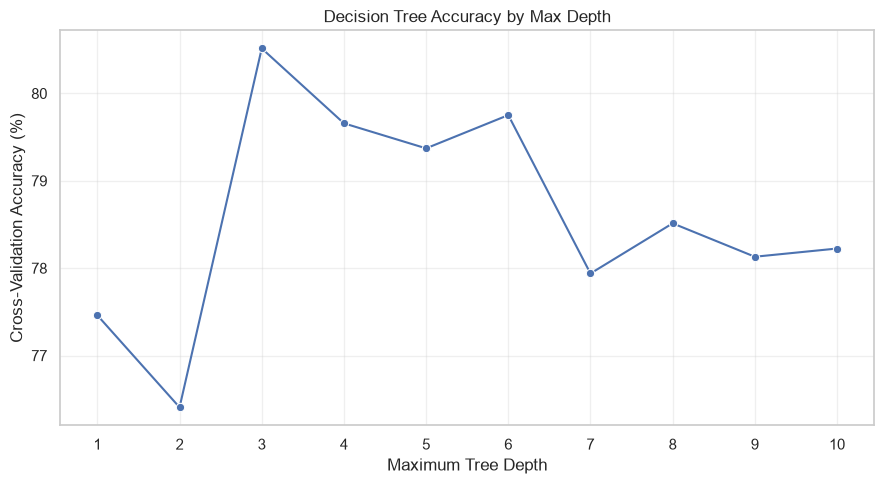

In [38]:

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=depth_df,
    x="max_depth",
    y="mean_accuracy",
    marker="o"
)

plt.title("Decision Tree Accuracy by Max Depth")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Cross-Validation Accuracy (%)")

plt.xticks(range(1, 11))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



#### Key Findings: Hyperparameter Tuning

**1. 최적 모델 깊이 선정**

- max_depth를 1부터 10까지 변경하여 5-Fold 교차검증을 수행했습니다.
- max_depth=3에서 가장 높은 평균 정확도인 약 80.51%를 기록했습니다.
- 따라서 현재 실험에서는 max_depth=3을 최적 후보로 선정했습니다.

**2. 모델 복잡도와 성능의 관계**

- max_depth=1~2에서는 상대적으로 낮은 예측 정확도가 나타났습니다.
- max_depth=3에서 교차검증 정확도가 가장 높았습니다.
- max_depth가 7 이상으로 증가하면 정확도가 약 78% 수준으로 감소했습니다.
- 모델의 복잡도가 증가한다고 반드시 예측 성능이 향상되는 것은 아님을 확인했습니다.

**3. 분석 결과 및 시사점**

- 단순한 의사결정나무 구조가 현재 데이터에서 더 높은 검증 정확도를 보였습니다.
- 복잡도가 높은 모델에서는 과적합 가능성을 추가로 검토할 필요가 있습니다.
- 모델 선정 시 훈련 정확도뿐 아니라 교차검증 성능을 고려하는 것이 중요합니다.

#### Next Step

선정된 max_depth=3을 활용하여 최종 모델을 학습하고,
주요 예측 변수의 중요도를 분석합니다.



### 4.6 Feature Importance Analysis

의사결정나무 모델이 승객의 생존 여부를 예측할 때
어떤 변수를 중요하게 활용하는지 분석합니다.

본 프로젝트에서는 교차검증 결과를 바탕으로
max_depth=3을 최종 모델의 하이퍼파라미터로 선정했습니다.

Feature Importance를 활용하여 각 변수가
의사결정나무의 예측 과정에 기여한 상대적 중요도를 확인합니다.

분석 목적은 다음과 같습니다.

1. 생존 여부 예측에 중요하게 사용된 변수 확인
2. 변수별 상대적 중요도 비교
3. 탐색적 데이터 분석(EDA) 결과와 머신러닝 결과 비교
4. 모델의 해석 가능성과 한계 검토

단, Feature Importance는 변수와 생존 여부 사이의
인과관계를 의미하지 않습니다.


In [39]:

# 최종 Decision Tree 모델 구축

final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

# 전체 훈련 데이터로 최종 모델 학습
final_model.fit(X_train, y_train)

print("최종 Decision Tree 모델 학습 완료!")


최종 Decision Tree 모델 학습 완료!


In [40]:

# 전처리 후 변수명 추출
feature_names = (
    final_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# 의사결정나무의 변수 중요도 추출
importances = (
    final_model.named_steps["classifier"]
    .feature_importances_
)

# 변수 중요도 데이터프레임 생성
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# 중요도가 높은 순서로 정렬
feature_importance_df = (
    feature_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# 백분율 변환
feature_importance_df["Importance (%)"] = (
    feature_importance_df["Importance"] * 100
)

display(feature_importance_df.round(2))


,Feature,Importance,Importance (%)
0,cat__sex_female,0.63,62.76
1,num__pclass,0.19,19.24
2,num__family_size,0.07,7.24
3,num__fare,0.05,5.48
4,num__age,0.05,5.27
5,num__parch,0.00,0.00
6,num__sibsp,0.00,0.00
7,cat__sex_male,0.00,0.00
8,cat__embarked_C,0.00,0.00
9,cat__embarked_Q,0.00,0.00


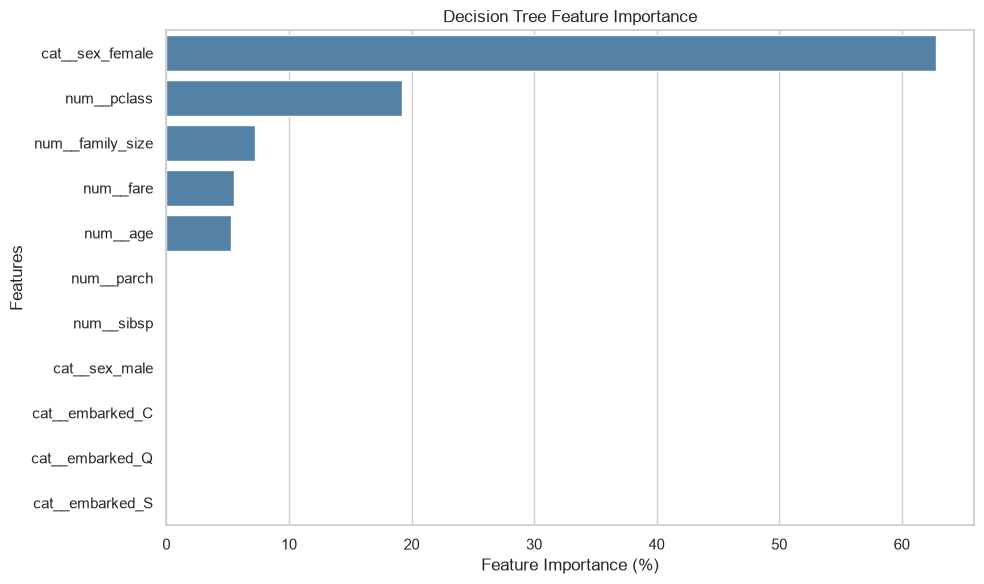

In [41]:

# 변수 중요도 시각화

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df,
    x="Importance (%)",
    y="Feature",
    color="steelblue"
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Feature Importance (%)")
plt.ylabel("Features")

plt.tight_layout()
plt.show()



#### Key Findings: Feature Importance

**1. 주요 예측 변수**

- 성별 관련 변수(sex_female)가 약 63%로 가장 높은 중요도를 보였습니다.
- 객실 등급(pclass)이 약 19%로 두 번째로 높았습니다.
- 가족 규모(family_size), 운임(fare), 나이(age)도 예측에 활용되었습니다.

**2. EDA와 머신러닝 결과 비교**

- EDA에서 여성의 생존율은 72.7%, 남성은 19.1%로 나타났습니다.
- 머신러닝에서도 성별이 가장 중요한 분기 기준으로 사용되었습니다.
- 객실 등급과 가족 규모 역시 생존율 분석과 머신러닝에서 의미 있는 차이를 보여주었습니다.

**3. 모델 해석 및 한계**

- Feature Importance는 의사결정나무의 불순도 감소에 기반한 상대적 중요도입니다.
- 중요도가 높다는 사실이 해당 변수의 인과적 영향을 의미하지는 않습니다.
- 중요도가 0인 변수도 다른 모델이나 다른 조건에서는 예측에 활용될 수 있습니다.
- 가족 규모는 sibsp와 parch를 조합한 파생변수이므로 변수 간 정보 중복 가능성이 있습니다.

#### Next Step

최종 모델의 예측 성능을 정리하고,
전체 데이터 분석 결과와 머신러닝 결과를 종합하여
프로젝트의 최종 결론을 도출합니다.



## 5. Final Model Evaluation

탐색적 데이터 분석과 머신러닝 모델 구축을 완료한 후,
최종 Decision Tree 모델의 예측 성능을 평가합니다.

5-Fold 교차검증 결과를 바탕으로 max_depth=3을 선정했으며,
훈련 데이터 전체를 활용하여 최종 모델을 학습했습니다.

최종 모델의 성능은 별도로 분리한 테스트 데이터에서 평가합니다.

평가 지표는 다음과 같습니다.

- Accuracy: 전체 예측 중 올바르게 예측한 비율
- Precision: 생존자로 예측한 승객 중 실제 생존한 비율
- Recall: 실제 생존자 중 생존자로 정확하게 예측한 비율
- F1-score: Precision과 Recall의 조화평균

최종 평가 결과를 통해 모델의 예측 성능과 한계를 종합적으로 검토합니다.


In [42]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 최종 모델의 테스트 데이터 예측
final_pred = final_model.predict(X_test)

# 최종 모델 평가 지표
final_accuracy = accuracy_score(y_test, final_pred)
final_precision = precision_score(y_test, final_pred)
final_recall = recall_score(y_test, final_pred)
final_f1 = f1_score(y_test, final_pred)

# 결과 출력
print("=== Final Decision Tree Performance ===")
print(f"Accuracy:  {final_accuracy * 100:.2f}%")
print(f"Precision: {final_precision * 100:.2f}%")
print(f"Recall:    {final_recall * 100:.2f}%")
print(f"F1-score:  {final_f1 * 100:.2f}%")

print("\n=== Confusion Matrix ===")
print(confusion_matrix(y_test, final_pred))


=== Final Decision Tree Performance ===
Accuracy:  83.59%
Precision: 81.32%
Recall:    74.00%
F1-score:  77.49%

=== Confusion Matrix ===
[[145  17]
 [ 26  74]]


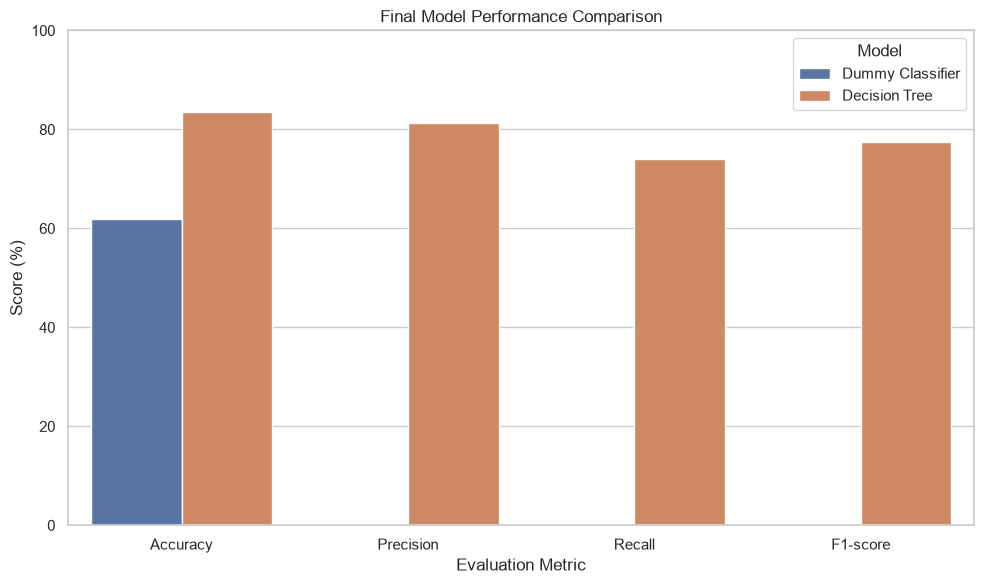

,Metric,Dummy Classifier,Decision Tree
0,Accuracy,61.83,83.59
1,Precision,0.00,81.32
2,Recall,0.00,74.00
3,F1-score,0.00,77.49


In [43]:

# 최종 모델과 기준 모델의 성능 비교
final_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Dummy Classifier": [
        accuracy_score(y_test, dummy_pred) * 100,
        precision_score(y_test, dummy_pred, zero_division=0) * 100,
        recall_score(y_test, dummy_pred, zero_division=0) * 100,
        f1_score(y_test, dummy_pred, zero_division=0) * 100
    ],
    "Decision Tree": [
        final_accuracy * 100,
        final_precision * 100,
        final_recall * 100,
        final_f1 * 100
    ]
})

# 그래프용 데이터 변환
comparison_long = final_comparison.melt(
    id_vars="Metric",
    var_name="Model",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Final Model Performance Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.legend(title="Model")

plt.tight_layout()
plt.show()

display(final_comparison.round(2))



## 6. Conclusion & Limitations

### 6.1 Project Summary

본 프로젝트는 타이타닉 승객 1,309명의 데이터를 활용하여
생존 여부와 관련된 주요 특성을 탐색하고,
머신러닝을 통해 생존 여부를 예측하는 것을 목표로 진행했습니다.

Python과 Pandas를 활용하여 데이터를 탐색하고,
Matplotlib과 Seaborn으로 생존 패턴을 시각화했습니다.

이후 결측치 처리, 범주형 변수 인코딩, 파생변수 생성 등의
전처리를 수행하고 Decision Tree 모델을 구축했습니다.

### 6.2 Key Findings

**1. 성별에 따른 생존율 차이**

- 여성 생존율: 약 72.7%
- 남성 생존율: 약 19.1%
- 여성의 생존율이 남성보다 약 53.6%p 높았습니다.
- 머신러닝에서도 성별이 가장 중요한 예측 변수로 나타났습니다.

**2. 객실 등급에 따른 생존 패턴**

- 객실 등급에 따라 생존율에 차이가 나타났습니다.
- 객실 등급은 머신러닝에서 두 번째로 높은 변수 중요도를 기록했습니다.
- 이는 객실 등급이 생존 여부 예측에 활용되는 주요 변수임을 보여줍니다.

**3. 연령대별 생존율 차이**

- 영유아(0~5세)의 생존율은 약 66.1%로 가장 높았습니다.
- 60세 이상 승객의 생존율은 30.0%로 가장 낮았습니다.
- 연령 증가에 따라 생존율이 일관되게 감소하는 패턴은 나타나지 않았습니다.

**4. 가족 규모에 따른 생존 패턴**

- 혼자 탑승한 승객의 생존율은 30.25%였습니다.
- 가족 동반 승객의 생존율은 50.29%였습니다.
- 가족 규모 4명인 집단에서 약 69.77%의 생존율을 기록했습니다.
- 가족 규모 역시 머신러닝 모델의 예측에 활용되었습니다.

### 6.3 Machine Learning Results

**1. 모델 성능**

- Dummy Classifier 정확도: 61.83%
- Decision Tree 정확도: 83.59%
- 정확도 향상: 21.76%p

**2. 교차검증**

- 5-Fold 교차검증 평균 정확도: 80.51%
- 표준편차: 1.44%p
- 서로 다른 훈련·검증 데이터 구성에서도 비교적 일관된 성능을 확인했습니다.

**3. 하이퍼파라미터 튜닝**

- max_depth를 1부터 10까지 비교했습니다.
- max_depth=3에서 가장 높은 교차검증 정확도를 기록했습니다.
- 모델 복잡도를 높인다고 반드시 성능이 개선되는 것은 아니었습니다.

**4. 최종 모델 평가**

- Accuracy: 83.59%
- Precision: 81.32%
- Recall: 74.00%
- F1-score: 77.49%

### 6.4 Limitations

**1. 데이터 결측치**

- 전체 승객 1,309명 중 나이 정보가 누락된 승객은 263명이었습니다.
- 결측치를 중앙값으로 대체했으므로 실제 연령 분포를 완전히 반영하지 못할 수 있습니다.
- 연령대별 EDA에서는 나이 결측치를 제외하여 분석했습니다.

**2. 모델의 일반화 가능성**

- 단일 데이터셋과 한 번의 훈련·테스트 분할을 기반으로 평가했습니다.
- 5-Fold 교차검증을 수행했지만, 외부 데이터에 대한 예측 성능은 검증하지 못했습니다.

**3. 알고리즘 비교의 한계**

- Dummy Classifier와 Decision Tree를 중심으로 모델을 비교했습니다.
- Logistic Regression, Random Forest 등 다른 알고리즘과의 성능 비교는 수행하지 않았습니다.

**4. 변수 중요도 해석의 한계**

- Feature Importance는 예측 과정에서의 상대적 중요도를 나타냅니다.
- 변수 중요도가 높다고 해서 해당 변수가 생존에 직접적인 영향을 미쳤다고 단정할 수 없습니다.

### 6.5 Future Improvements

향후 다음과 같은 방법으로 프로젝트를 개선할 수 있습니다.

1. Logistic Regression과 Random Forest 등 추가 모델 비교
2. GridSearchCV를 활용한 하이퍼파라미터 탐색 확대
3. 가족 규모 및 승객 특성을 활용한 추가 파생변수 생성
4. 생존자 Recall과 F1-score 중심의 성능 개선
5. 외부 데이터셋을 활용한 모델 일반화 성능 검증

### 6.6 Final Conclusion

본 프로젝트에서는 탐색적 데이터 분석을 통해
성별, 객실 등급, 연령, 가족 규모에 따른 생존 패턴을 확인했습니다.

이후 데이터 전처리와 머신러닝 모델 구축을 통해
기준 모델 대비 정확도를 21.76%p 향상시켰습니다.

또한 교차검증과 하이퍼파라미터 튜닝을 통해
모델의 성능과 안정성을 검토하고,
Feature Importance 분석을 통해 주요 예측 변수를 해석했습니다.

이를 통해 단순한 데이터 시각화를 넘어
문제 정의, 데이터 탐색, 전처리, 모델 구축, 성능 평가,
결과 해석으로 이어지는 데이터 분석 프로세스를 수행했습니다.
